![](img/banner.png)

# High-Dimensional Data and the Curse of Dimensionality

**Mahmood Amintoosi, Fall 2026**

Computer Science Dept, Ferdowsi University of Mashhad

The geometric facts on this page are those of *The Elements of Statistical Learning*
({cite}`hastie2009elements`), §2.5, and chapter 6 of Zaki's *Data Mining and Machine
Learning* ({cite}`zaki2020data`).

**Learning objectives.** By the end you should be able to

1. compute the volume of a ball and of a cube in $d$ dimensions and explain why their ratio
   tends to zero;
2. explain why a neighbourhood containing a fixed fraction of the data is not local in high
   dimensions, and compute its edge length $e_d(r) = r^{1/d}$;
3. show that in high dimension the nearest and the farthest neighbour are almost equally
   far away, and say what that does to k-NN;
4. explain why most of the volume of a ball is in a thin shell, and why Gaussian samples
   concentrate at radius $\sqrt{d}$;
5. sample points uniformly inside a ball and on its surface (why the naive radius is wrong);
6. measure the effect of the dimension on a k-NN classifier, with and without more data.

## Introduction

In modern data mining and machine learning we often deal with data in very
high-dimensional spaces (images, text embeddings, genomic data). A dataset is typically
represented as an $n \times d$ matrix $\mathbf{D}$: $n$ points, $d$ features.

High-dimensional space, or **hyperspace**, does not behave like the geometry of two or three
dimensions. The collection of effects that follow from this is called the **curse of
dimensionality**. The five phenomena we look at are:

1. **Volume concentration**: the volume of a hypersphere vanishes relative to the hypercube
   that contains it.
2. **The problem of local neighborhoods**: a "local" neighbourhood of a fixed fraction of
   the data is not local any more, so methods such as k-NN lose their meaning (ESL §2.5).
3. **Distance concentration**: the nearest and the farthest neighbour are almost at the same
   distance, so ranking neighbours becomes meaningless.
4. **The thin shell**: almost all of the volume of a ball sits near its surface.
5. **Orthogonality and Gaussian behaviour**: random vectors are nearly orthogonal, and
   Gaussian samples concentrate in a thin shell at radius $\sqrt{d}$.

Throughout, $d$ is the number of dimensions. The figures taken from ESL label it $p$; the
text here uses $d$ consistently.

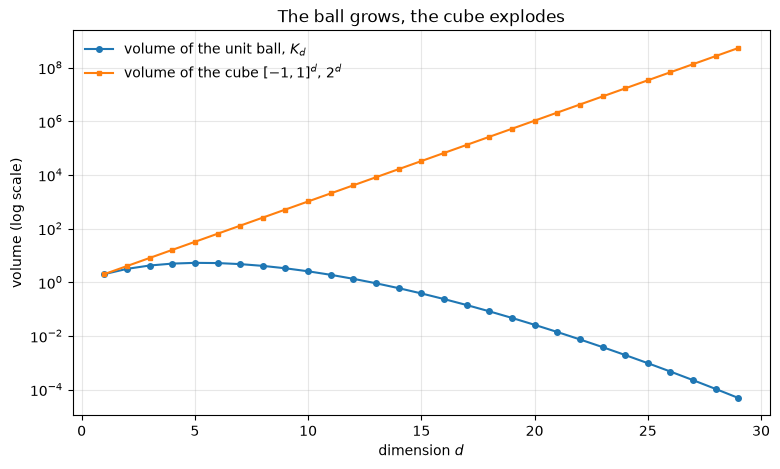

d =  1:  ball volume = 2.000e+00   ratio ball/cube = 1.000e+00
d =  2:  ball volume = 3.142e+00   ratio ball/cube = 7.854e-01
d =  3:  ball volume = 4.189e+00   ratio ball/cube = 5.236e-01
d = 10:  ball volume = 2.550e+00   ratio ball/cube = 2.490e-03
d = 20:  ball volume = 2.581e-02   ratio ball/cube = 2.461e-08


In [1]:
import math

import matplotlib.pyplot as plt
import numpy as np

SEED = 42
rng = np.random.default_rng(SEED)


def ball_volume(d, r=1.0):
    """Volume of the d-dimensional ball of radius r: K_d * r^d."""
    return math.pi ** (d / 2) * r ** d / math.gamma(d / 2 + 1)


def shell_volume(d, r=1.0, thickness=0.2):
    """Volume of the shell of the given thickness just inside the surface."""
    return ball_volume(d, r) - ball_volume(d, max(r - thickness, 0.0))


dimensions = range(1, 30)
plt.figure(figsize=(9, 5))
plt.plot(list(dimensions), [ball_volume(d) for d in dimensions], marker="o", ms=4,
         label=r"volume of the unit ball, $K_d$")
plt.plot(list(dimensions), [2.0 ** d for d in dimensions], marker="s", ms=3,
         label=r"volume of the cube $[-1,1]^d$, $2^d$")
plt.yscale("log")
plt.xlabel("dimension $d$")
plt.ylabel("volume (log scale)")
plt.title("The ball grows, the cube explodes")
plt.legend(frameon=False)
plt.grid(alpha=0.3)
plt.show()

for d in [1, 2, 3, 10, 20]:
    print(f"d = {d:2d}:  ball volume = {ball_volume(d):.3e}   "
          f"ratio ball/cube = {ball_volume(d) / 2 ** d:.3e}")

## Geometry of Hyperspace: Cubes and Balls

### The Hypercube

The data space is often taken as a $d$-dimensional hypercube. For a hypercube $H_d(l)$ of
side length $l$ the volume is simply

$$
\operatorname{Vol}\big(H_d(l)\big) = l^d .
$$

### The Ball and the Sphere

Two different objects are needed, and confusing them is a classic source of errors:

* the **ball** $B_d(r) = \{\mathbf{x} : \|\mathbf{x}\| \le r\}$ is the solid; its volume is

$$
\operatorname{Vol}\big(B_d(r)\big) = K_d\, r^d,
\qquad
K_d = \frac{\pi^{d/2}}{\Gamma\!\left(\frac{d}{2}+1\right)} ;
$$

* the **sphere** $S^{d-1}(r) = \{\mathbf{x} : \|\mathbf{x}\| = r\}$ is only the surface — a
  set of measure zero — and is written with $d-1$ because it is a $(d-1)$-dimensional
  object living in $\mathbb{R}^d$. Its area is $d K_d r^{d-1}$, the derivative of the
  volume with respect to $r$.

$\Gamma$ is the Gamma function; for integer arguments $\Gamma(m) = (m-1)!$.

![](img/Figure-6.4-Zaki.png)

*Figure 6.4. A hypersphere inscribed in a hypercube: (a) two and (b) three dimensions
(Zaki, ch. 6).*

### The Empty Center (the "Porcupine" Effect)

Take the largest ball that fits inside a cube of side $l = 2r$, that is $B_d(r)$. The ratio
of their volumes is

$$
\frac{\operatorname{Vol}\big(B_d(r)\big)}{\operatorname{Vol}\big(H_d(2r)\big)}
= \frac{\pi^{d/2}}{2^d\,\Gamma\!\left(\frac{d}{2}+1\right)}
\;\xrightarrow[d \to \infty]{}\; 0 .
$$

**Implication.** As the dimension grows, the ball becomes negligible compared with the cube:
almost all of the volume of the cube is in its **corners**, and the center is essentially
empty. In $d$ dimensions there are $2^d$ corners.

![Corners in High Dimension](img/Figure-6.5-Zaki.png)

*Conceptual view of high-dimensional space: (a) two, (b) three, (c) four and (d) higher
dimensions. In $d$ dimensions there are $2^d$ corners; the radius of the inscribed ball is
what makes the difference between the volume of the cube and of the ball visible (Zaki,
ch. 6).*

## The Problem of Local Neighborhoods

One of the most consequential manifestations of the curse of dimensionality is that "local"
methods such as k-nearest neighbours stop being local.

### The Edge Length of a Neighborhood

Suppose the inputs are uniformly distributed in the unit hypercube $[0,1]^d$ and we want a
neighbourhood that contains a fraction $r$ of the observations. That neighbourhood must
cover a fraction $r$ of the volume, and if it is a subcube of edge length $e_d(r)$ then

$$
\big(e_d(r)\big)^d = r
\qquad\Longrightarrow\qquad
e_d(r) = r^{1/d} .
$$

![](img/Figure-2.6-ESL.png)

*Figure 2.6 (ESL). The side length of the subcube needed to capture a fraction $r$ of the
volume of the data, for different dimensions $p$ (the figure labels the dimension $p$; here
it is $d$). In ten dimensions we must cover 80% of the range of each coordinate to capture
10% of the data.*

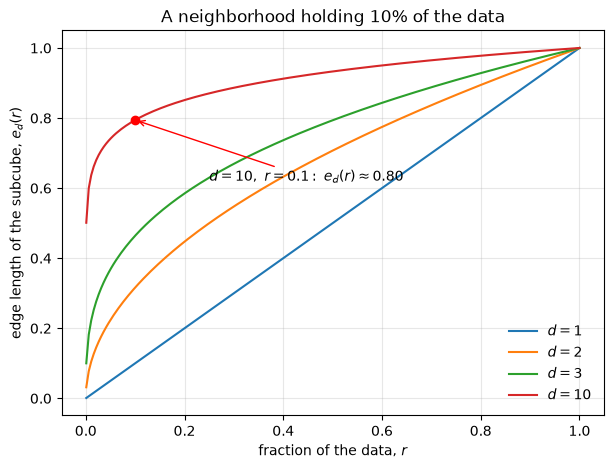

In [2]:
def edge_length(fraction, d):
    return fraction ** (1.0 / d)


fractions = np.linspace(0.001, 1.0, 200)
plt.figure(figsize=(7, 5))
for d in [1, 2, 3, 10]:
    plt.plot(fractions, edge_length(fractions, d), label=f"$d={d}$")

plt.plot(0.1, 0.1 ** (1 / 10), "ro")
plt.annotate(r"$d=10,\ r=0.1:\ e_d(r)\approx 0.80$", (0.1, 0.1 ** (1 / 10)),
             xytext=(0.25, 0.62), arrowprops=dict(arrowstyle="->", color="red"))
plt.xlabel(r"fraction of the data, $r$")
plt.ylabel(r"edge length of the subcube, $e_d(r)$")
plt.title("A neighborhood holding 10% of the data")
plt.legend(frameon=False)
plt.grid(alpha=0.3)
plt.show()

**Analysis.** With $d = 10$ and $r = 0.1$ we need $e_{10}(0.1) = 0.1^{0.1} \approx 0.80$:
to capture 10% of the data we must cover **80% of the range of every coordinate**. Such a
neighbourhood is not local in any useful sense — it is most of the space.

### Distance to the Boundary

Sampling density is sparse for a second reason. For $N$ points drawn uniformly in the unit
ball $B_d(1)$, the median distance from the origin to the closest data point is

$$
d(d, N) = \left(1 - \left(\tfrac{1}{2}\right)^{1/N}\right)^{1/d} .
$$

**Where the formula comes from.** The probability that a single uniform point falls in the
ball of radius $t$ is $t^d$, so the probability that it falls outside is $1 - t^d$, and the
probability that **all** $N$ points fall outside is $(1 - t^d)^N$. The median of the
distance to the closest point is the $t$ for which that probability equals $1/2$:

$$
(1 - t^d)^N = \tfrac{1}{2}
\;\Longrightarrow\;
t = \left(1 - \left(\tfrac{1}{2}\right)^{1/N}\right)^{1/d} .
$$

For $N = 500$ and $d = 10$ this gives $\approx 0.52$: more than halfway to the boundary.
Hence **most data points are closer to the boundary of the sample space than to any other
data point**, and prediction is a problem of *extrapolation* rather than of interpolation.

## Distance Concentration

The phenomenon that hurts k-NN most directly is not the edge length but the distances
themselves. For a query point, let $d_{\min}$ be the distance to its nearest neighbour and
$d_{\max}$ the distance to the farthest point of the sample. In one dimension the ratio
$d_{\min}/d_{\max}$ is small: there is a genuinely close point. In high dimensions the ratio
tends to $1$: the closest point is almost as far as the farthest one, so "nearest" is a
statement about noise rather than about similarity.

The experiment below draws $n$ points uniformly in the unit cube for $d = 2, 10, 100, 1000$,
takes one random query point, and reports the mean ratio $d_{\min}/d_{\max}$ over many
queries.

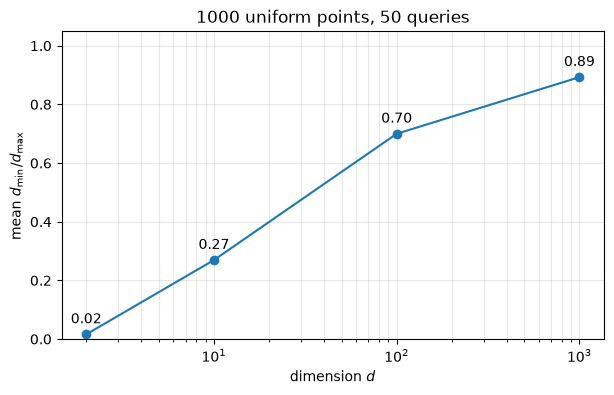

d =    2:  mean d_min/d_max = 0.016
d =   10:  mean d_min/d_max = 0.269
d =  100:  mean d_min/d_max = 0.700
d = 1000:  mean d_min/d_max = 0.893


In [3]:
n_points, n_queries = 1000, 50
dims_dc = [2, 10, 100, 1000]
ratios = []

for d in dims_dc:
    data = rng.random((n_points, d))
    queries = rng.random((n_queries, d))
    dist = np.linalg.norm(queries[:, None, :] - data[None, :, :], axis=2)
    ratios.append(np.mean(dist.min(axis=1) / dist.max(axis=1)))

plt.figure(figsize=(7, 4))
plt.plot(dims_dc, ratios, marker="o")
for x, y in zip(dims_dc, ratios):
    plt.annotate(f"{y:.2f}", (x, y), textcoords="offset points", xytext=(0, 8), ha="center")
plt.xscale("log")
plt.xlabel("dimension $d$")
plt.ylabel(r"mean $d_{\min}/d_{\max}$")
plt.title(f"{n_points} uniform points, {n_queries} queries")
plt.ylim(0, 1.05)
plt.grid(alpha=0.3, which="both")
plt.show()

for d, ratio in zip(dims_dc, ratios):
    print(f"d = {d:4d}:  mean d_min/d_max = {ratio:.3f}")

Read the numbers: in two dimensions the nearest neighbour is typically a small fraction of
the farthest distance, so ranking neighbours is informative. In a thousand dimensions the
ratio is close to $1$ — **every point is almost equidistant from every other point**. Two
consequences:

* The neighbour ranking is dominated by noise: which point is "nearest" changes with tiny
  perturbations of the data, so a k-NN vote is unstable.
* A ball around the query that contains $k$ neighbours is so large that it contains a good
  part of the data, so the "local" average is not local.

This is the theoretical reason behind the experiment at the end of this page.

## The Thin Shell Argument

Where is the volume inside a ball? Consider a thin shell of width $\epsilon$ just inside
the surface of a ball of radius $r$. Its volume is

$$
\operatorname{Vol}\big(B_d(r)\big) - \operatorname{Vol}\big(B_d(r-\epsilon)\big)
= K_d\left(r^d - (r-\epsilon)^d\right),
$$

so the fraction of the volume in the shell is

$$
\frac{\operatorname{Vol}(\text{shell})}{\operatorname{Vol}\big(B_d(r)\big)}
= 1 - \left(1 - \frac{\epsilon}{r}\right)^{d}
\;\xrightarrow[d\to\infty]{}\; 1 .
$$

![](img/Figure-6.6-Zaki.png)

*Figure 6.6 (Zaki, ch. 6): the shell of a ball concentrates the volume as $d$ grows.*

> For a disk ($d=2$) with $r=1$ and $\epsilon=0.01$ the shell holds
> $1-0.99^2 \approx 2\%$ of the area. For $d=100$ the same shell holds
> $1-0.99^{100} \approx 0.63$ — almost two thirds.

**Conclusion.** In high dimensions, for a shell of fixed relative thickness $\epsilon/r$,
almost **100% of the volume** — and of the probability mass of a uniform distribution — is
concentrated near the surface. The interior is essentially empty.

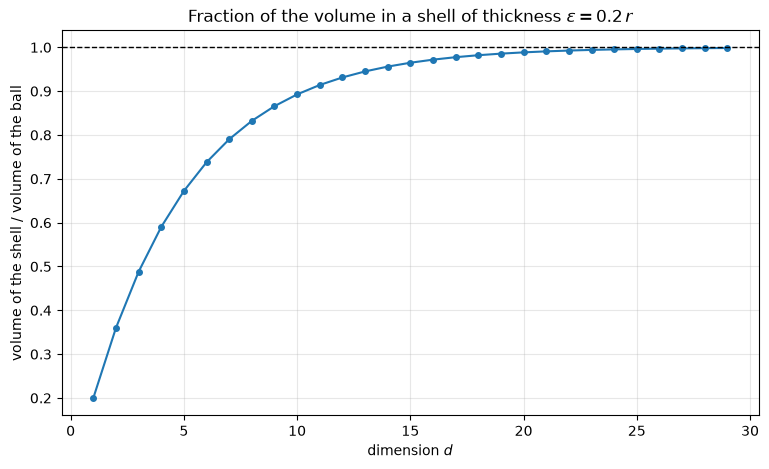

d =  2:  shell fraction = 0.360
d = 10:  shell fraction = 0.893
d = 30:  shell fraction = 0.999


In [4]:
dims_shell = list(range(1, 30))
fraction = [shell_volume(d, 1.0, 0.2) / ball_volume(d, 1.0) for d in dims_shell]

plt.figure(figsize=(9, 5))
plt.plot(dims_shell, fraction, marker="o", ms=4)
plt.axhline(1.0, color="black", lw=1, ls="--")
plt.xlabel("dimension $d$")
plt.ylabel(r"volume of the shell / volume of the ball")
plt.title(r"Fraction of the volume in a shell of thickness $\epsilon = 0.2\,r$")
plt.grid(alpha=0.3)
plt.show()

for d in [2, 10, 30]:
    print(f"d = {d:2d}:  shell fraction = {shell_volume(d, 1.0, 0.2) / ball_volume(d, 1.0):.3f}")

## Aside: Sampling Points Uniformly in a Ball

Generating points uniformly inside a ball in high dimensions is a good illustration of the
volume facts above, and it is needed by many simulation experiments.

**Rejection sampling** — generate points uniformly in the cube and keep those inside the
ball — has an acceptance rate equal to the ratio of the two volumes, which goes to zero (the
porcupine effect). Beyond about ten dimensions it is computationally useless. The table
below measures the acceptance rate for $d = 2, \dots, 10$ with 2000 accepted points, and
compares it with the theoretical value $K_d/2^d$.

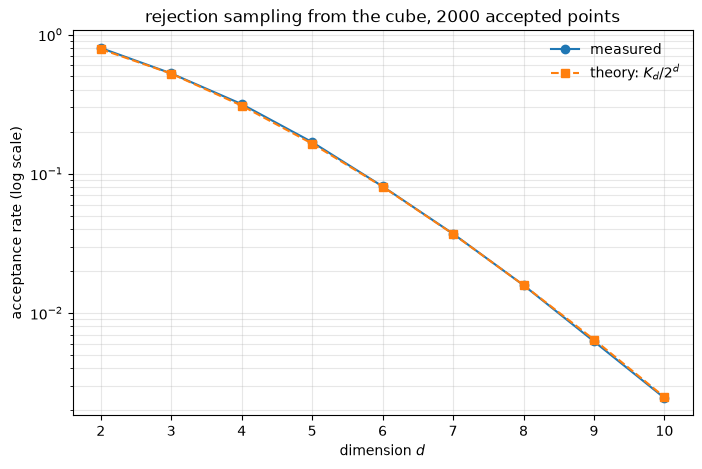

d =  2:  measured = 0.8003   theory = 0.7854   candidates per accepted point =      1.2
d =  3:  measured = 0.5255   theory = 0.5236   candidates per accepted point =      1.9
d =  4:  measured = 0.3163   theory = 0.3084   candidates per accepted point =      3.2
d =  5:  measured = 0.1687   theory = 0.1645   candidates per accepted point =      5.9
d =  6:  measured = 0.0811   theory = 0.0807   candidates per accepted point =     12.3
d =  7:  measured = 0.0371   theory = 0.0369   candidates per accepted point =     27.0
d =  8:  measured = 0.0158   theory = 0.0159   candidates per accepted point =     63.2
d =  9:  measured = 0.0062   theory = 0.0064   candidates per accepted point =    160.0
d = 10:  measured = 0.0025   theory = 0.0025   candidates per accepted point =    408.0


In [5]:
def rejection_rate(num_points, d, batch_size=1000, max_batches=20000):
    """Acceptance rate of rejection sampling: how much of the cube is in the ball?"""
    accepted, generated = 0, 0
    for _ in range(max_batches):
        batch = rng.uniform(-1, 1, (batch_size, d))
        accepted += int(np.sum(np.sum(batch ** 2, axis=1) <= 1.0))
        generated += batch_size
        if accepted >= num_points:
            break
    return accepted / generated


n_points = 2000
dims_rej = list(range(2, 11))
measured, theoretical = [], []

for d in dims_rej:
    measured.append(rejection_rate(n_points, d))
    theoretical.append(ball_volume(d) / 2 ** d)

plt.figure(figsize=(8, 5))
plt.plot(dims_rej, measured, marker="o", label="measured")
plt.plot(dims_rej, theoretical, marker="s", ls="--", label=r"theory: $K_d/2^d$")
plt.yscale("log")
plt.xlabel("dimension $d$")
plt.ylabel("acceptance rate (log scale)")
plt.title(f"rejection sampling from the cube, {n_points} accepted points")
plt.legend(frameon=False)
plt.grid(alpha=0.3, which="both")
plt.show()

for d, m, t in zip(dims_rej, measured, theoretical):
    print(f"d = {d:2d}:  measured = {m:.4f}   theory = {t:.4f}   "
          f"candidates per accepted point = {1 / m:8.1f}")

The measured rate falls off geometrically and follows $K_d/2^d$: by $d=10$ only about one
candidate point in four hundred lands inside the ball, and the cost per accepted point
keeps doubling with every extra dimension.

### Points on the Surface: Gaussian Directions

The trick that makes uniform sampling easy is to use the **spherical symmetry** of the
Gaussian distribution. If $x_i \sim \mathcal{N}(0,1)$ independently, the joint density is

$$
f(\mathbf{x}) = \prod_{i=1}^d \frac{1}{\sqrt{2\pi}} e^{-x_i^2/2}
= \frac{1}{(2\pi)^{d/2}} e^{-\|\mathbf{x}\|^2/2},
$$

which depends on the length $\|\mathbf{x}\|$ only, never on the direction. The distribution is
therefore invariant under rotations (*isotropic*), all directions are equally likely, and

$$
\mathbf{y} = \frac{\mathbf{x}}{\|\mathbf{x}\|}
$$

is uniformly distributed on the unit sphere $S^{d-1}(1)$.

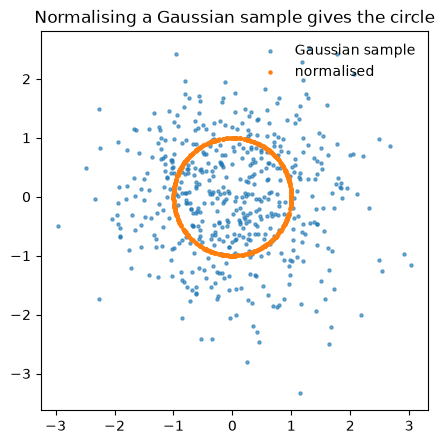

In [6]:
n_dir = 500
d_vis = 2

x = rng.standard_normal((n_dir, d_vis))
y_surface = x / np.linalg.norm(x, axis=1, keepdims=True)

plt.figure(figsize=(5, 5))
plt.scatter(x[:, 0], x[:, 1], s=5, alpha=0.6, label="Gaussian sample")
plt.scatter(y_surface[:, 0], y_surface[:, 1], s=5, label="normalised")
plt.gca().set_aspect("equal")
plt.title("Normalising a Gaussian sample gives the circle")
plt.legend(frameon=False, loc="upper right")
plt.show()

### Points Inside the Ball

Scaling a direction by a uniform random number $\rho \sim U(0,1)$ is **wrong**: the volume
of a shell at radius $t$ grows like $t^{d-1}$, so most of the volume is near the surface and
a uniform radius bunches the points near the center.

**The right radius.** For the uniform distribution inside the ball, the probability that a
point lies within radius $t$ must be proportional to the volume it encloses:

$$
F(t) = P(R \le t) = \frac{\operatorname{Vol}(B_d(t))}{\operatorname{Vol}(B_d(1))}
= \frac{K_d t^d}{K_d} = t^d .
$$

Inverse transform sampling with $a \sim U(0,1)$ then gives $\rho = F^{-1}(a) = a^{1/d}$.
For $d=2$, $\rho = \sqrt{a}$:

| $a \sim U(0,1)$ | 0.00 | 0.10 | 0.25 | 0.50 | 0.75 | 1.00 |
|---|---|---|---|---|---|---|
| $\rho = \sqrt{a}$ | 0.000 | 0.316 | 0.500 | 0.707 | 0.866 | 1.000 |

**Algorithm for uniform points in the ball $B_d(1)$:**

1. draw $\mathbf{x} \sim \mathcal{N}(0, I_d)$;
2. normalise, $\mathbf{y} = \mathbf{x}/\|\mathbf{x}\|$ — a uniform direction;
3. draw $a \sim U(0,1)$;
4. return $a^{1/d}\,\mathbf{y}$.

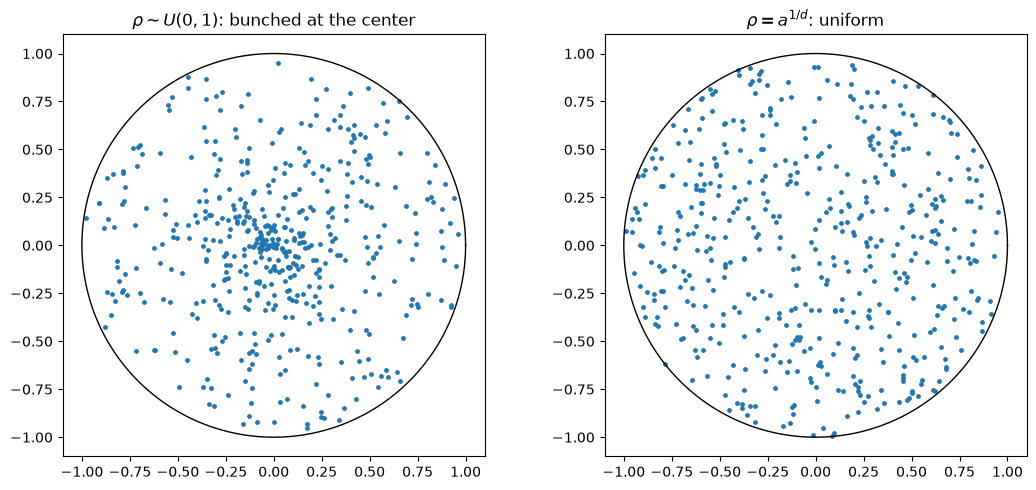

d =  2, naive  : fraction with rho < 0.5 = 0.4967   (expected 0.2500)
d =  2, correct: fraction with rho < 0.5 = 0.2479   (expected 0.2500)
d =  3, naive  : fraction with rho < 0.5 = 0.4966   (expected 0.1250)
d =  3, correct: fraction with rho < 0.5 = 0.1240   (expected 0.1250)
d = 10, naive  : fraction with rho < 0.5 = 0.5015   (expected 0.0010)
d = 10, correct: fraction with rho < 0.5 = 0.0009   (expected 0.0010)


In [7]:
d_ball = 2
plt.figure(figsize=(11, 5))

for panel, exponent in enumerate([1.0, 1.0 / d_ball]):
    a = rng.random(n_dir)
    rho = a ** exponent
    points = rho[:, None] * y_surface

    plt.subplot(1, 2, panel + 1)
    theta = np.linspace(0, 2 * np.pi, 400)
    plt.plot(np.cos(theta), np.sin(theta), color="black", lw=1)
    plt.scatter(points[:, 0], points[:, 1], s=6)
    plt.gca().set_aspect("equal")
    plt.title(r"$\rho \sim U(0,1)$: bunched at the center" if panel == 0
              else r"$\rho = a^{1/d}$: uniform")
    plt.xlim(-1.1, 1.1)
    plt.ylim(-1.1, 1.1)

plt.tight_layout()
plt.show()

# a quantitative check: the fraction of points inside half the radius must be (1/2)^d
for d in [2, 3, 10]:
    a = rng.random(20000)
    for name, rho in [("naive", a), ("correct", a ** (1 / d))]:
        print(f"d = {d:2d}, {name:7s}: fraction with rho < 0.5 = "
              f"{np.mean(rho < 0.5):.4f}   (expected {(0.5) ** d:.4f})")

## Nearly Orthogonal Directions

Another counter-intuitive property is that in high dimensions "every direction is
orthogonal to every other one", or more precisely: random vectors are nearly orthogonal.

### The Diagonal of the Hypercube

Consider the main diagonal of the cube, $\mathbf{1} = (1, 1, \dots, 1)^\top$. The angle
$\theta_d$ between it and a coordinate axis $\mathbf{e}_1 = (1, 0, \dots, 0)^\top$ satisfies

$$
\cos\theta_d = \frac{\mathbf{e}_1^\top \mathbf{1}}{\|\mathbf{e}_1\|\,\|\mathbf{1}\|}
= \frac{1}{\sqrt{d}}
\;\xrightarrow[d\to\infty]{}\; 0,
$$

so $\theta_d \to 90^\circ$: the diagonal is almost orthogonal to every axis.

### Random Vectors

The same holds for two independent random vectors, and the reason is the law of large
numbers: for $\mathbf{x}, \mathbf{y}$ with independent zero-mean, unit-variance entries,

$$
\frac{\mathbf{x}^\top \mathbf{y}}{\|\mathbf{x}\|\,\|\mathbf{y}\|}
\approx \frac{\sum_i x_i y_i}{\sqrt{d}\,\sqrt{d}},
$$

whose numerator is a sum of $d$ independent zero-mean terms of variance $1$ and therefore of
size $\sqrt{d}$ — the ratio is $O(1/\sqrt{d})$.

In [8]:
dim = 200
vectors = rng.standard_normal((5, dim))
vectors /= np.linalg.norm(vectors, axis=1, keepdims=True)

cosines = [vectors[i] @ vectors[j]
           for i in range(len(vectors)) for j in range(i + 1, len(vectors))]
print(f"cosine similarities of {len(cosines)} random pairs in {dim}-D:")
print(np.round(cosines, 4))
print(f"max |cosine| = {np.max(np.abs(cosines)):.4f}   (1/sqrt(d) = {1 / np.sqrt(dim):.4f})")

cosine similarities of 10 random pairs in 200-D:
[-0.0401  0.0349 -0.0056 -0.0042 -0.075  -0.0497 -0.0402  0.0836  0.0071
  0.1518]
max |cosine| = 0.1518   (1/sqrt(d) = 0.0707)


## Gaussian Distribution in High Dimensions

### From Geometric Shells to Statistical Shells

The geometric effects above were about the volume of a ball. The Gaussian distribution shows
the same phenomenon statistically: even though its density is maximal at the origin, almost
no sample lands near the origin.

### Why Gaussian Points Do Not Cluster Near the Mean

Let $\mathbf{x} = (x_1, \dots, x_d) \sim \mathcal{N}(0, I_d)$. In one dimension many samples
lie "close to zero", and $|x|$ is usually small. This intuition breaks down from two
dimensions on: the **density** is highest at the origin, but the **volume** available near
the origin is negligible.

* In one dimension "the center" is a point and there is no volume growth.
* In $d$ dimensions the volume of a shell grows like $r^{d-1}$, so the number of points at
  radius $r$ is density $\times$ volume.

> The center has the highest density but almost no volume, so almost no sample lands there.

### Distance of a Gaussian Vector from the Origin

A single identity explains the behaviour:

$$
\|\mathbf{x}\|^2 = \sum_{i=1}^d x_i^2 \sim \chi^2_d,
\qquad
\mathbb{E}\|\mathbf{x}\|^2 = d,
\qquad
\mathbb{E}\|\mathbf{x}\| \approx \sqrt{d}.
$$

So $\|\mathbf{x}\| \approx 0.8$ for $d=1$, $\approx 1.41$ for $d=2$, $\approx 3.16$ for
$d=10$ and $\approx 14.1$ for $d=200$ (see
[chi-squared distribution](https://en.wikipedia.org/wiki/Chi-squared_distribution)).
Increasing the dimension pushes **all** samples outward, not just the outliers: the whole
distribution sits in a thin shell around radius $\sqrt{d}$.

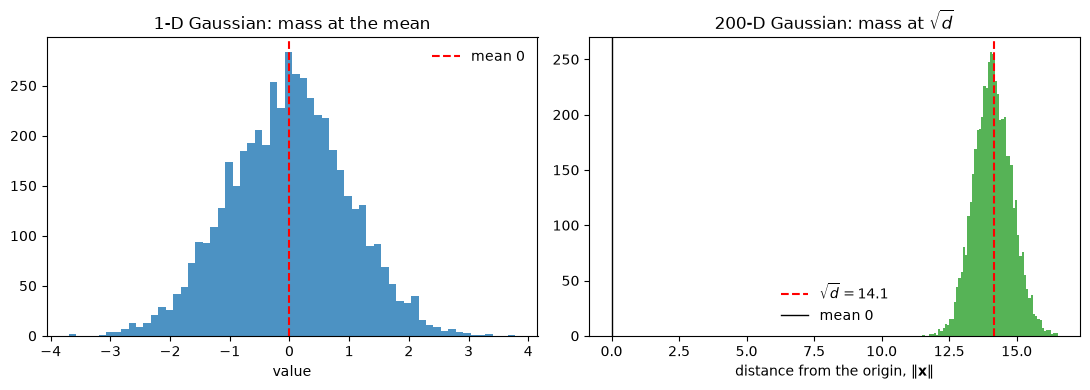

mean norm = 14.12   std = 0.70   sqrt(d) = 14.14
fraction of samples with norm within 10% of sqrt(d): 0.96


In [9]:
d_gauss = 200
n_gauss = 5000

x_1d = rng.standard_normal(n_gauss)
norms = np.linalg.norm(rng.standard_normal((n_gauss, d_gauss)), axis=1)

fig, ax = plt.subplots(1, 2, figsize=(11, 4))
ax[0].hist(x_1d, bins=60, color="tab:blue", alpha=0.8)
ax[0].axvline(0, color="red", ls="--", label="mean 0")
ax[0].set_title("1-D Gaussian: mass at the mean")
ax[0].set_xlabel("value")
ax[0].legend(frameon=False)

ax[1].hist(norms, bins=60, color="tab:green", alpha=0.8)
ax[1].axvline(np.sqrt(d_gauss), color="red", ls="--",
              label=rf"$\sqrt{{d}} = {np.sqrt(d_gauss):.1f}$")
ax[1].axvline(0, color="black", lw=1, label="mean 0")
ax[1].set_title(rf"{d_gauss}-D Gaussian: mass at $\sqrt{{d}}$")
ax[1].set_xlabel(r"distance from the origin, $\|\mathbf{x}\|$")
ax[1].legend(frameon=False)
plt.tight_layout()
plt.show()

print(f"mean norm = {norms.mean():.2f}   std = {norms.std():.2f}   sqrt(d) = {np.sqrt(d_gauss):.2f}")
print(f"fraction of samples with norm within 10% of sqrt(d): "
      f"{np.mean(np.abs(norms - np.sqrt(d_gauss)) < 0.1 * np.sqrt(d_gauss)):.2f}")

The two histograms are the statistical version of the geometric thin-shell effect: one-
dimensional Gaussian data sit at the mean, two-hundred-dimensional Gaussian data sit on a
sphere of radius $14.1$ with a width that does not grow with $d$.

## The Gaussian Annulus Phenomenon

The formal statement is:

> With overwhelming probability a Gaussian sample lies within
> $\sqrt{d} \pm O(1)$ of the origin — a thin annulus whose thickness does *not* grow with
> $d$.

As $d$ increases the radius grows like $\sqrt{d}$ while the thickness stays constant, so the
relative thickness tends to zero. This is the reason Gaussian vectors are used in theory:
they *are* the geometry of high-dimensional space, in the same way that uniform points in a
ball are.

### Connection with the Previous Sections

| earlier result | Gaussian version |
|---|---|
| the center of the ball is empty | Gaussian mass avoids the origin |
| uniform volume concentrates at the surface | Gaussian mass concentrates at $\sqrt{d}$ |
| uniform sampling needs $\rho = a^{1/d}$ | Gaussian sampling does this automatically |
| random vectors are nearly orthogonal | normalised Gaussian vectors are near-orthogonal |

### Why This Matters

Because almost all Gaussian vectors have length $\approx \sqrt{d}$, two independent Gaussian
vectors $\mathbf{x}, \mathbf{y}$ satisfy $\|\mathbf{x} - \mathbf{y}\|^2 \approx 2d$, with a
relative spread that shrinks as $d$ grows: **pairwise distances are stable**, and dot products
between normalised vectors are small. These two facts are what makes random projections work,
and they are the properties we come back to when we discuss random projections and the
Johnson–Lindenstrauss lemma later in the course.

## k-NN under the Curse of Dimensionality

The distance-concentration argument predicts that k-NN degrades as the dimension grows — and
that the degradation can be compensated by more data. The experiment below tests both
predictions on synthetic data with `make_classification`:

* **row 1: $n$ fixed** ($n = 600$) while $d$ grows from 2 to 200. Only two features are
  informative (`n_informative=2`); the remaining $d-2$ are noise. With $n$ fixed, more
  dimensions mean more noise and fewer points per dimension.
* **row 2: $n$ grows with $d$** ($n = 100\,d$), so the number of points per dimension stays
  constant. If the curse is about density rather than about dimension itself, this should
  recover the accuracy.

Each configuration is repeated over five seeds, and the plots show the mean accuracy with a
$\pm 1$ standard-deviation band. The classifier is 5-NN on standardised features.

fixed n = 600 d =   2  n =    600   accuracy = 0.934 +- 0.039
fixed n = 600 d =   5  n =    600   accuracy = 0.903 +- 0.040
fixed n = 600 d =  10  n =    600   accuracy = 0.850 +- 0.039
fixed n = 600 d =  25  n =    600   accuracy = 0.773 +- 0.034
fixed n = 600 d =  50  n =    600   accuracy = 0.667 +- 0.052
fixed n = 600 d = 100  n =    600   accuracy = 0.608 +- 0.041
fixed n = 600 d = 200  n =    600   accuracy = 0.594 +- 0.022


n = 100 d     d =   2  n =    200   accuracy = 0.963 +- 0.036
n = 100 d     d =   5  n =    500   accuracy = 0.929 +- 0.057
n = 100 d     d =  10  n =   1000   accuracy = 0.878 +- 0.048
n = 100 d     d =  25  n =   2500   accuracy = 0.824 +- 0.075
n = 100 d     d =  50  n =   5000   accuracy = 0.737 +- 0.047
n = 100 d     d = 100  n =  10000   accuracy = 0.671 +- 0.016
n = 100 d     d = 200  n =  20000   accuracy = 0.627 +- 0.029


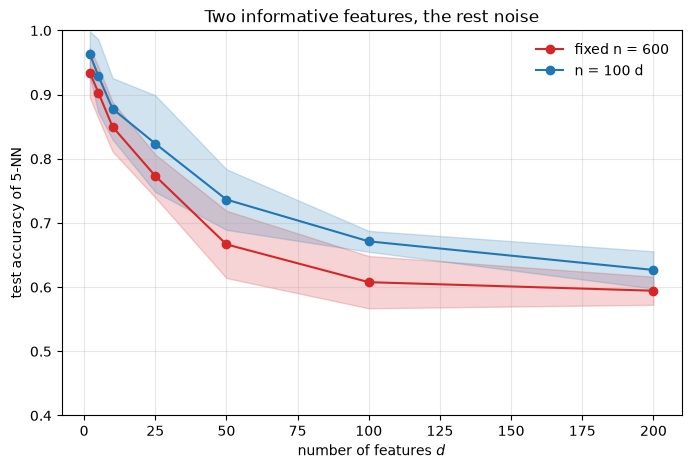

In [10]:
from sklearn.datasets import make_classification
from sklearn.metrics import accuracy_score
from sklearn.model_selection import train_test_split
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler

dims_knn = [2, 5, 10, 25, 50, 100, 200]
seeds = range(5)


def knn_accuracy(d, n_samples, seed):
    X_, y_ = make_classification(n_samples=n_samples, n_features=d, n_informative=2,
                                 n_redundant=0, n_classes=2, n_clusters_per_class=1,
                                 class_sep=1.0, flip_y=0.01, random_state=seed)
    X_tr, X_te, y_tr, y_te = train_test_split(X_, y_, test_size=0.3, random_state=seed,
                                              stratify=y_)
    model = make_pipeline(StandardScaler(), KNeighborsClassifier(n_neighbors=5))
    return accuracy_score(y_te, model.fit(X_tr, y_tr).predict(X_te))


curves = {}
for label, size in [("fixed n = 600", lambda d: 600),
                    ("n = 100 d", lambda d: 100 * d)]:
    scores = np.array([[knn_accuracy(d, size(d), s) for d in dims_knn] for s in seeds])
    curves[label] = (scores.mean(axis=0), scores.std(axis=0))
    for d, mean, std in zip(dims_knn, *curves[label]):
        print(f"{label:13s} d = {d:3d}  n = {size(d):6d}   accuracy = {mean:.3f} +- {std:.3f}")

plt.figure(figsize=(8, 5))
for (label, (mean, std)), color in zip(curves.items(), ["tab:red", "tab:blue"]):
    plt.plot(dims_knn, mean, marker="o", color=color, label=label)
    plt.fill_between(dims_knn, mean - std, mean + std, color=color, alpha=0.2)
plt.xlabel("number of features $d$")
plt.ylabel("test accuracy of 5-NN")
plt.title("Two informative features, the rest noise")
plt.ylim(0.4, 1.0)
plt.legend(frameon=False)
plt.grid(alpha=0.3)
plt.show()

The first curve falls as the dimension grows although the informative structure never
changes: the two useful features are still there, but they are buried among $d-2$ noise
features, and the distances that k-NN trusts are dominated by the noise.

The second curve tests whether more data is the cure. It helps — every value is a little
better than the corresponding point of the first curve — but it does **not** stop the decay:
the accuracy still falls from about $0.96$ at $d=2$ to about $0.63$ at $d=200$, with 33 times
more data. More data buys density, and density was not the binding constraint here: the
binding constraint is that nearly all coordinates are noise, so the distance concentration
of the previous sections is a property of the *distribution*, not only of the sample size.

The practical consequence is the one ESL draws in §2.5: for high-dimensional data, k-NN must
be preceded by something that removes or down-weights the uninformative directions — feature
selection, PCA, or a learned metric. Adding points is useful, but it is not a substitute.

## Summary

* High-dimensional space is **empty in the center**: the volume of the ball is negligible
  compared with the cube, and almost all of the cube's volume is in its $2^d$ corners.
* A neighbourhood holding a fixed fraction $r$ of the points has edge length
  $e_d(r) = r^{1/d}$: in ten dimensions, 10% of the data needs 80% of the range of every
  coordinate.
* **Distances concentrate**: $d_{\min}/d_{\max} \to 1$, so neighbour rankings become noise
  and k-NN degrades — *unless* $n$ grows with $d$.
* Most of the volume of a ball is in a thin shell of fixed relative thickness, and Gaussian
  samples concentrate at radius $\sqrt{d}$ with a thickness that does not grow with $d$.
* Uniform sampling in a ball needs the radius $\rho = a^{1/d}$; the easy way is a Gaussian
  direction times that radius. Rejection sampling dies exponentially.
* Random vectors are nearly orthogonal, and pairwise distances are stable — the properties
  behind random projections.

## References

* {cite}`hastie2009elements`, §2.5 (local methods in high dimensions, Figure 2.6) and §2.9
  (model assessment).
* {cite}`zaki2020data`, chapter 6 (high-dimensional space, Figures 6.4–6.6).
* Blum, Hopcroft and Kannan, *Foundations of Data Science*, chapter 2 (concentration of
  measure, random projections).